# Illustrating Badgers for testing ML predictors

End-to-end walk-through of the paper experiment, step by step:

1. **Data** — `make_data()`: four corner blobs with columns `(x, y, cls)`
2. **Split** — stratified 50/50 train/test (`split_data`)
3. **Direct (non-causal) deficits** — generators applied to the test half: drift, noise, outliers
4. **Causal deficits** — the same deficits injected through the SCM fitted on the train half (`build_dgp`), so a $do$-intervention on $x$ propagates to $y$
5. **Predictors + impact table** — RandomForestClassifier / RandomForestRegressor / IsolationForest fitted once on the clean train half, evaluated on every deficit variant
6. **Decision maps and regression curves** — frozen classifier and detector maps over clean/direct/causal data, plus class-conditioned Random Forest regression curves for predicting $y$ from $(x, cls)$

Requires the `badgers` package and the causal generators' optional `dowhy` extra (`pip install badgers[dowhy]`).

## Setup — building blocks for the experiment

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, to_rgb
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from sklearn.inspection import DecisionBoundaryDisplay

from numpy.random import default_rng


In [2]:
SEED = 42
# Okabe-Ito palette (color-vision-deficiency safe) + B/W-distinguishable markers
CLASS_COLORS = ["#0072B2", "#E69F00", "#009E73", "#D55E00"]
CLASS_MARKERS = ["o", "s", "^", "D"]

### Visualization helpers

In [3]:
def scatter_classes(ax, X, y, *, observed=None, ms=6.0, edgecolor=None,
                    mew=None, color_fn=None):
    observed = np.ones(len(X), dtype=bool) if observed is None else observed
    for cls, (color, marker) in enumerate(zip(CLASS_COLORS, CLASS_MARKERS)):
        ix = (y == cls) & observed
        ax.plot(X[ix, 0], X[ix, 1], marker,
                color=color if color_fn is None else color_fn(color),
                markersize=ms, markeredgecolor=edgecolor,
                markeredgewidth=0.0 if mew is None else mew, linestyle="none")


def caption(ax, text, handle):
    ax.legend([handle], [text], loc="lower right", bbox_to_anchor=(1, 0.02),
              frameon=False, fontsize=12, labelcolor="0.35",
              handlelength=1.0, handletextpad=0.4, borderaxespad=0)


def outlier_marks(ax, X, y, mask, wrong=None, ms=8.0,
                  show_caption=True):
    """Appended outlier rows as x-marks, colored by their class; rows in
    `wrong` in a darker shade."""
    if wrong is not None:
        wrong = np.asarray(wrong, dtype=bool)
    for cls, color in enumerate(CLASS_COLORS):
        m = mask & (y == cls)
        if wrong is None:
            groups = [(m, color)]
        else:
            groups = [(m & ~wrong, color), (m & wrong, darken(color))]
        for m_, color_ in groups:
            if m_.any():
                ax.plot(X[m_, 0], X[m_, 1], "x", color=color_, markersize=ms,
                        markeredgewidth=2.0, linestyle="none")
    if show_caption:
        caption(ax, "outlier rows",
                Line2D([], [], marker="x", color="0.35", markersize=ms,
                       markeredgewidth=2.0, linestyle="none"))


CLASS_HANDLES = [
    Line2D([], [], marker=m, color=c, linestyle="none", markersize=7.0,
           label=f"class {i}")
    for i, (c, m) in enumerate(zip(CLASS_COLORS, CLASS_MARKERS))
]


def class_legend(fig):
    fig.legend(handles=CLASS_HANDLES, loc="outside upper left", ncols=4,
               fontsize=12, frameon=False, handlelength=1.0,
               handletextpad=0.4)

## Data generation — four diagonal corner blobs

`make_data` builds four Gaussian blobs at the corners
$(\pm1, \pm1)$ — 400 points total. One seed (`SEED = 42`) drives a single RNG
stream that draws, blob by blob, isotropic noise scaled by the vector
$\mathrm{scales} = (0.5, 0.2)$ and then rotated by $45°$ via the matrix $R$. 
Each blob is elongated along the main diagonal.

In [4]:
def make_data(n_samples=400):
    '''
    Corner blobs whose per-class scatter is elongated along the main diagonal.
    '''
    n_per_blob = n_samples // 4
    centers = [(-1, -1), (1, -1), (-1, 1), (1, 1)]
    rotation = np.array([[np.cos(np.pi / 4), -np.sin(np.pi / 4)],
                         [np.sin(np.pi / 4), np.cos(np.pi / 4)]])
    scales = np.array([0.5, 0.2])
    rng = default_rng(SEED)
    X = np.vstack([np.asarray(c) + (rng.normal(size=(n_per_blob, 2)) * scales) @ rotation.T
                   for c in centers])
    y = np.repeat(np.arange(4), n_per_blob)
    X = np.hstack([X, y.astype(float).reshape(-1, 1)])
    return X, y

def align_y(Xt, y, sc):
    '''Class labels aligned with the generated output.

    Outlier rows are appended copies of seed rows: their cls cell is NOT a
    selector target, so it still carries the seed row's class.
    '''
    if sc.observed is None:
        return y
    return np.concatenate([y, Xt[len(y):, 2].astype(int)])

### Generatring the data

Four Gaussian blobs at the corners $(\pm1, \pm1)$, elongated along the main
diagonal (scales $0.5 \times 0.2$, rotated $45°$).
`X` has three columns
$(x, y, \mathrm{cls})$; `y` is the class index $0..3$.

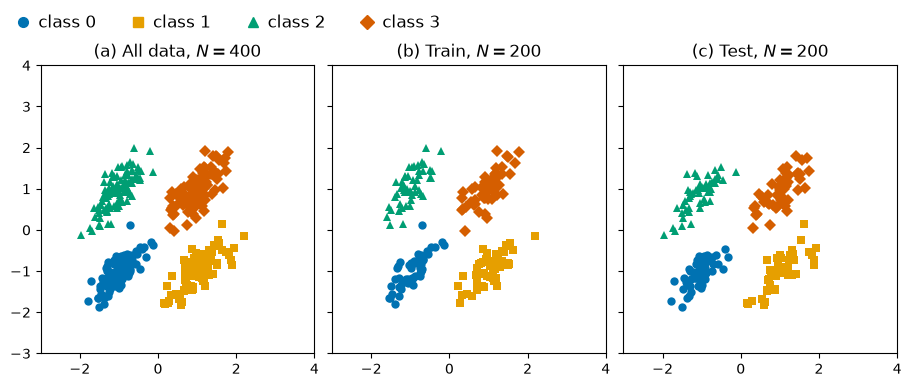

In [5]:
from sklearn.model_selection import train_test_split
X, y = make_data()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, stratify=y, random_state=SEED)

fig, axes = plt.subplots(1, 3, figsize=(9.0, 3.8), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (label, Xd, yd) in zip(
        axes, [("(a) All data, $N=400$", X, y),
               ("(b) Train, $N=200$", X_train, y_train),
               ("(c) Test, $N=200$", X_test, y_test)]):
    scatter_classes(ax, Xd, yd)
    ax.set_title(label)
    ax.set_xlim(-3, 4)
    ax.set_ylim(-3, 4)
class_legend(fig)

### Fitting the causal data-generating process (SCM)

`build_dgp` wraps a *structural causal model* (SCM) in a badgers
`GcmSCMDGP` so the causal generators can inject defects and propagate them
through the learned mechanism. 

The graph encodes:
- $\mathrm{cls} \to x$,
- $\mathrm{cls} \to y$
- $x \to y$


**root "cls"** gets `EmpiricalDistribution` — it just resamples observed
  class values.

**"x"** gets an `AdditiveNoiseModel` whose prediction model is a pipeline
  `OneHotEncoder → LinearRegression` — i.e. the learned conditional mean
  $\mathbb{E}[x \mid \mathrm{cls}]$ (one mean per blob) plus the fitted
  noise term, so $x = f_x(\mathrm{cls}) + N_x$.

**"y"** gets an `AdditiveNoiseModel` over the feature block
  `OneHotEncoder(cls) ⊕ passthrough(x)` followed by a linear regression —
  i.e. $y = f_y(\mathrm{cls}, x) + N_y$, capturing both the class offset and
  the diagonal tilt. This is the edge that makes a $do$-intervention on $x$
  propagate to $y$.

`GcmSCMDGP(scm, COLUMN_MAPPING).fit(X)` maps the column names to positions
(`x` → 0, `y` → 1, `cls` → 2) and fits all noise models on the clean train
half; the resulting `dgp` object is what the causal generators in section 4
consume. Needs the optional `dowhy` extra.

In [6]:
# variable name -> column index of the (x, y, cls) design matrix
COLUMN_MAPPING = {"x": 0, "y": 1, "cls": 2}

def build_dgp(X):
    '''Fit the shared SCM  cls -> x, cls -> y, x -> y  on the clean data.'''
    import dowhy.gcm as gcm
    import networkx as nx
    from sklearn.compose import ColumnTransformer
    from sklearn.linear_model import LinearRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import OneHotEncoder
    from dowhy.gcm.ml.regression import SklearnRegressionModel

    from badgers.core.dgp.backends.gcm_scm import GcmSCMDGP

    graph = nx.DiGraph([("cls", "x"), ("cls", "y"), ("x", "y")])
    scm = gcm.StructuralCausalModel(graph)
    scm.set_causal_mechanism("cls", gcm.EmpiricalDistribution())
    feature_block = ColumnTransformer(
        [("ohe", OneHotEncoder(), [0]), ("keep", "passthrough", [1])])
    scm.set_causal_mechanism(
        "x", gcm.AdditiveNoiseModel(
            prediction_model=SklearnRegressionModel(
                make_pipeline(OneHotEncoder(), LinearRegression()))))
    scm.set_causal_mechanism(
        "y", gcm.AdditiveNoiseModel(
            prediction_model=SklearnRegressionModel(
                make_pipeline(feature_block, LinearRegression()))))
    return GcmSCMDGP(scm, COLUMN_MAPPING).fit(X)

## Applying the generators

Every deficit below is run as a *scenario*: a name, a family tag
(`direct` / `causal` / `reference`), and the generated test set. Two pieces
of glue are needed around the generators:

- `Scenario` is a small state holder; `sc.observed` records, as a boolean
  mask aligned with the generated output, which rows are *original* rows
  (`True`) and which are *appended outlier* rows (`False`). In-place
  generators (drift, noise) leave it `None` — all rows are original.
- `_FrozenSpec` is an adapter for the noise generator: instead of a selector
  object it hands over an already-computed boolean spec of which cells to
  corrupt, so the noise lands exactly on the cells selected upstream
  (figure bookkeeping, kept for reproducibility with the paper contract).

In [7]:
class _FrozenSpec:
    '''Hands a pre-realized spec to the generator (figure bookkeeping).'''

    def __init__(self, spec):
        self.spec = spec

    def __call__(self, X, targets=None):
        return {0: self.spec}


class Scenario:
    def __init__(self, name, family):
        self.name = name
        self.family = family
        # bool mask aligned with the generated output; None = all rows are
        # original rows (in-place generators)
        self.observed = None

### The six deficit scenarios

Three deficits × two injection layers (plus the untouched baseline), each a function `fn(X, y, sc, dgp) -> Xt` that applies the exact
generators of the paper figures to the test data:

- **direct drift** — `FixedShiftClassesGenerator` moves the class-1 rows by
  the absolute vector `shift={1: (1.0, 0.0)}` on the columns
  `variables=[0, 1]` (so $x \leftarrow x+1$, $y \leftarrow y$, no
  propagation); `ClassSelector` picks the affected rows in class-1 proportion.
- **direct noise** — `AdditiveNoiseGenerator` adds $\mathcal{N}(0, 0.5^2)$
  (scale × `noise_std=1.0`) to the class-1 `x` cells; the cells are selected
  up front and passed through `_FrozenSpec`.
- **direct outliers** — `OutlierSamplingGenerator` appends `count=20` rows
  drawn from `JointHistogramSampler`'s low-density bins — regions where the
  seed data has almost no support. `sc.observed` records the 200 original vs
  20 appended rows (`~gen.get_outliers_labels()`).
- **causal variants** — the *same* three deficits, but as $do$-interventions
  routed through the fitted SCM (`dgp=dgp`): `CausalDriftGenerator` shifts $x$
  by `shift_amount * std(x)`, `CausalNoiseGenerator` adds relative noise
  `noise_std=0.5`, and `CausalOutlierPropagationGenerator` replaces $x$ of the
  20 seed rows with OOD values and re-samples their descendants ($y$) through
  the SCM. Each causal call re-derives the class-proportion selector, so both
  layers hit the same rows.

`SCENARIOS` lists them in the order the impact table consumes; each entry is
instantiated into a fresh `Scenario` at run time so per-run state
(`observed`) never leaks between evaluations.

In [8]:
from numpy.random import default_rng
from scipy.stats import norm

from badgers.core.sampling import JointHistogramSampler
from badgers.core.selectors import ClassSelector, get_selected_fields
from badgers.core.selectors.value_free import CountSelector
from badgers.generators.tabular_data.drift import FixedShiftClassesGenerator
from badgers.generators.tabular_data.drift.causal import CausalDriftGenerator
from badgers.generators.tabular_data.noise import AdditiveNoiseGenerator
from badgers.generators.tabular_data.noise.causal import CausalNoiseGenerator
from badgers.generators.tabular_data.outliers.causal import (
    CausalOutlierPropagationGenerator,
)
from badgers.generators.tabular_data.outliers.sampling import (
    OutlierSamplingGenerator,
)

def sc_baseline(X, y, sc, dgp):
    return X.copy()

def sc_drift_direct(X, y, sc, dgp):
    gen = FixedShiftClassesGenerator(random_generator=default_rng(0))
    return gen.generate(
        X.copy(),
        selector=ClassSelector([0], class_column=2,
                               proportions={1: (y == 1).mean()},
                               rng=default_rng(0)),
        shift={1: (1.0, 0.0)}, variables=[0, 1])

def sc_noise_direct(X, y, sc, dgp):
    rng = default_rng(42)
    gen = AdditiveNoiseGenerator(random_generator=rng)
    noisy = get_selected_fields(
        X,
        ClassSelector([0], class_column=2,
                      proportions={1: (y == 1).mean()}, rng=rng),
        rng,
    )[:, 0]
    return gen.generate(
        X.copy(), distribution=norm(loc=0, scale=0.5), noise_std=1.0,
        selector=_FrozenSpec(noisy))

def sc_outliers_direct(X, y, sc, dgp):
    gen = OutlierSamplingGenerator(random_generator=default_rng(0))
    Xt = gen.generate(
        X.copy(),
        selector=CountSelector([0], count=20, rng=default_rng(0)),
        out_of_distribution_sampler=JointHistogramSampler(
            bins=10, threshold_low_density=0.25),
    )
    sc.observed = ~gen.get_outliers_labels().astype(bool)
    return Xt

def sc_drift_causal(X, y, sc, dgp):
    gen = CausalDriftGenerator(random_generator=default_rng(10), dgp=dgp)
    return gen.generate(
        X.copy(),
        selector=ClassSelector([COLUMN_MAPPING["x"]],
                               class_column=COLUMN_MAPPING["cls"],
                               proportions={1: (y == 1).mean()},
                               rng=default_rng(0)),
        shift_amount=1.0)

def sc_noise_causal(X, y, sc, dgp):
    gen = CausalNoiseGenerator(random_generator=default_rng(42), dgp=dgp)
    return gen.generate(
        X.copy(),
        selector=ClassSelector([COLUMN_MAPPING["x"]],
                               class_column=COLUMN_MAPPING["cls"],
                               proportions={1: (y == 1).mean()},
                               rng=default_rng(42)),
        noise_std=0.5)

def sc_outliers_causal(X, y, sc, dgp):
    gen = CausalOutlierPropagationGenerator(
        random_generator=default_rng(0), dgp=dgp)
    Xt = gen.generate(
        X.copy(),
        selector=CountSelector(
            [COLUMN_MAPPING["x"]], count=20, rng=default_rng(0)),
        out_of_distribution_sampler=JointHistogramSampler(
            bins=10, threshold_low_density=0.25),
    )
    sc.observed = ~gen.get_outliers_labels().astype(bool)
    return Xt

SCENARIOS = [
    ("baseline", "reference", sc_baseline),
    ("drift", "direct", sc_drift_direct),
    ("noise", "direct", sc_noise_direct),
    ("outliers", "direct", sc_outliers_direct),
    ("drift", "causal", sc_drift_causal),
    ("noise", "causal", sc_noise_causal),
    ("outliers", "causal", sc_outliers_causal),
]

## Applying direct (non-causal) generators on the test data


In [9]:
def to_frame(Xt, sc):
    """Generated test data as an inspectable DataFrame.

    One row per generated row: the two feature columns, the true class
    (aligned via align_y) and an `outlier` flag for appended rows.
    """
    df = pd.DataFrame(Xt[:, :2], columns=["x", "y"])
    df["cls"] = align_y(Xt, y_test, sc).astype(int)
    if sc.observed is not None:
        df["outlier"] = ~sc.observed
    return df


def save_frames(frames, tag):
    """Write every scenario DataFrame as one CSV: <tag>-<scenario>.csv."""
    out = Path("generated-data")
    out.mkdir(exist_ok=True)
    for name, df in frames.items():
        df.to_csv(out / f"{tag}-{name}.csv", index=False)
    return out


In [10]:
# apply the three direct generators to the clean test half and keep
# the results: DIRECT (raw arrays, consumed by the figures below) and
# DIRECT_DATA (same rows as DataFrames, also written to generated-data/)
DIRECT = {}
for name, fn in (("drift", sc_drift_direct), ("noise", sc_noise_direct),
                 ("outliers", sc_outliers_direct)):
    sc = Scenario(name, "direct")
    DIRECT[name] = (fn(X_test, y_test, sc, None), sc)

DIRECT_DATA = {name: to_frame(Xt, sc) for name, (Xt, sc) in DIRECT.items()}
save_frames(DIRECT_DATA, "direct")
DIRECT_DATA


{'drift':             x         y  cls
 0    0.350248  0.544207    3
 1   -1.476227 -1.427412    0
 2   -1.136071 -0.817239    0
 3   -0.504159  1.533031    2
 4   -0.645329 -0.600909    0
 ..        ...       ...  ...
 195  2.060969 -0.809060    1
 196 -1.314292  0.434318    2
 197 -1.509834  0.406070    2
 198  1.778442 -0.738377    1
 199  0.729360  0.632531    3
 
 [200 rows x 3 columns],
 'noise':             x         y  cls
 0    0.350248  0.544207    3
 1   -1.476227 -1.427412    0
 2   -1.136071 -0.817239    0
 3   -0.504159  1.533031    2
 4   -0.645329 -0.600909    0
 ..        ...       ...  ...
 195  0.966667 -0.809060    1
 196 -1.314292  0.434318    2
 197 -1.509834  0.406070    2
 198  0.293139 -0.738377    1
 199  0.729360  0.632531    3
 
 [200 rows x 3 columns],
 'outliers':             x         y  cls  outlier
 0    0.350248  0.544207    3    False
 1   -1.476227 -1.427412    0    False
 2   -1.136071 -0.817239    0    False
 3   -0.504159  1.533031    2    False
 

### VIsualizing the generated test data

The clean test half (a) next to the three generated variants — the 2x2 grid
makes every change directly comparable against the original data.


drift     rows: 200
noise     rows: 200
outliers  rows: 220


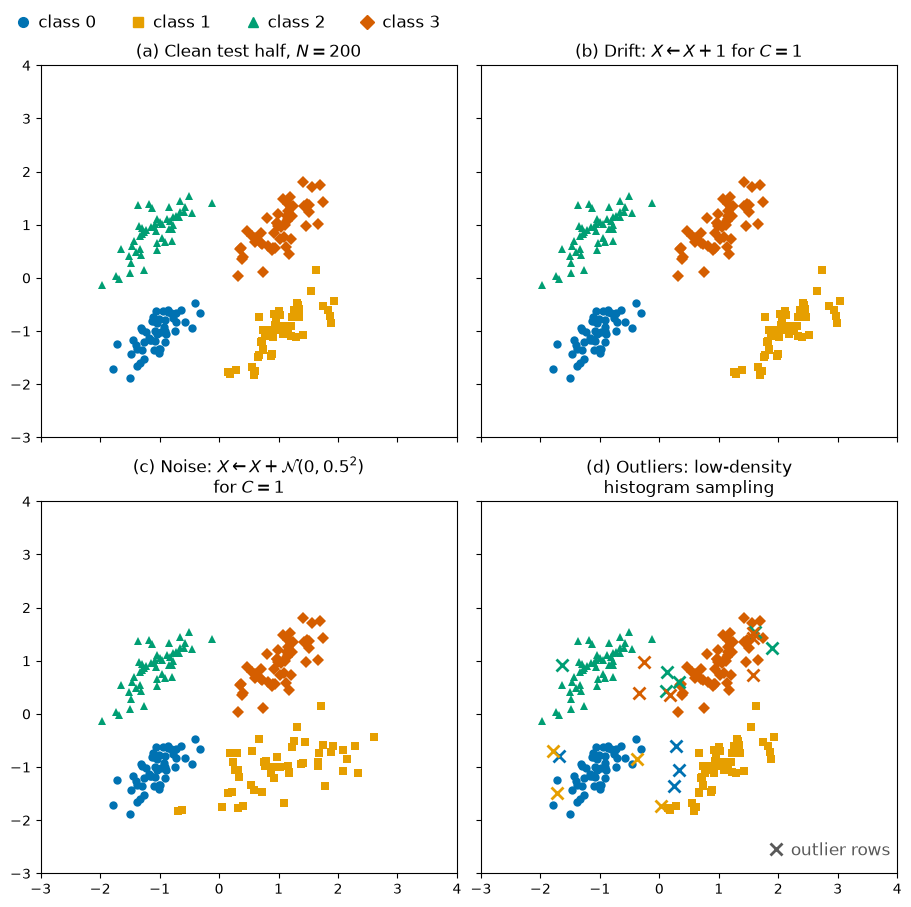

In [11]:
TITLES = {
    "drift": r"(b) Drift: $X \leftarrow X + 1$ for $C = 1$",
    "noise": (r"(c) Noise: $X \leftarrow X + \mathcal{N}(0, 0.5^2)$"
              "\n"
              r"for $C = 1$"),
    "outliers": (r"(d) Outliers: low-density"
                 "\n"
                 "histogram sampling"),
}
# 2x2 grid: panel (a) shows the untouched clean test half so every generated
# variant can be compared against the original data at a glance
fig, axes = plt.subplots(2, 2, figsize=(9.0, 9.0), sharex=True, sharey=True,
                         constrained_layout=True)
ax = axes[0, 0]
scatter_classes(ax, X_test, y_test)
ax.set_title(r"(a) Clean test half, $N=200$")
for ax, name in zip(axes.flat[1:], ("drift", "noise", "outliers")):
    Xt, sc = DIRECT[name]
    y_al = align_y(Xt, y_test, sc)
    if sc.observed is None:
        scatter_classes(ax, Xt, y_al)
    else:
        scatter_classes(ax, Xt, y_al, observed=sc.observed)
        outlier_marks(ax, Xt, y_al, ~sc.observed)
    ax.set_title(TITLES[name])
for ax in axes.flat:
    ax.set_xlim(-3, 4)
    ax.set_ylim(-3, 4)
class_legend(fig)
for name, (Xt, sc) in DIRECT.items():
    print(f"{name:9s} rows: {len(Xt)}")


## Applying causal generators on the test data

The same three deficits, but injected through the SCM
$\mathrm{cls} \to x$, $\mathrm{cls} \to y$, $x \to y$ fitted on the
**train** half (`build_dgp`), so a $do$-intervention on $x$ propagates to
$y$ as well.

In [12]:
# same as the direct cell, but the generators inject the deficits through
# the SCM (dgp) fitted on the clean train half
dgp = build_dgp(X_train)  # SCM fitted on the clean train half only

CAUSAL = {}
for name, fn in (("drift", sc_drift_causal), ("noise", sc_noise_causal),
                 ("outliers", sc_outliers_causal)):
    sc = Scenario(name, "causal")
    CAUSAL[name] = (fn(X_test, y_test, sc, dgp), sc)

CAUSAL_DATA = {name: to_frame(Xt, sc) for name, (Xt, sc) in CAUSAL.items()}
save_frames(CAUSAL_DATA, "causal")
CAUSAL_DATA


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node cls:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node x:   0%|          | 0/3 [00:00<?, ?it/s]  

Fitting causal mechanism of node y:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node y: 100%|██████████| 3/3 [00:00<00:00, 80.40it/s]

{'drift':             x         y  cls
 0    0.350248  0.544207    3
 1   -1.476227 -1.427412    0
 2   -1.136071 -0.817239    0
 3   -0.504159  1.533031    2
 4   -0.645329 -0.600909    0
 ..        ...       ...  ...
 195  2.060969 -0.052770    1
 196 -1.314292  0.434318    2
 197 -1.509834  0.406070    2
 198  1.778442 -0.407774    1
 199  0.729360  0.632531    3
 
 [200 rows x 3 columns],
 'noise':             x         y  cls
 0    0.350248  0.544207    3
 1   -1.476227 -1.427412    0
 2   -1.136071 -0.817239    0
 3   -0.504159  1.533031    2
 4   -0.645329 -0.600909    0
 ..        ...       ...  ...
 195  2.132627 -0.745100    1
 196 -1.314292  0.434318    2
 197 -1.509834  0.406070    2
 198 -0.044199 -1.768313    1
 199  0.729360  0.632531    3
 
 [200 rows x 3 columns],
 'outliers':             x         y  cls  outlier
 0    0.350248  0.544207    3    False
 1   -1.476227 -1.427412    0    False
 2   -1.136071 -0.817239    0    False
 3   -0.504159  1.533031    2    False
 

drift     rows: 200
noise     rows: 200
outliers  rows: 220


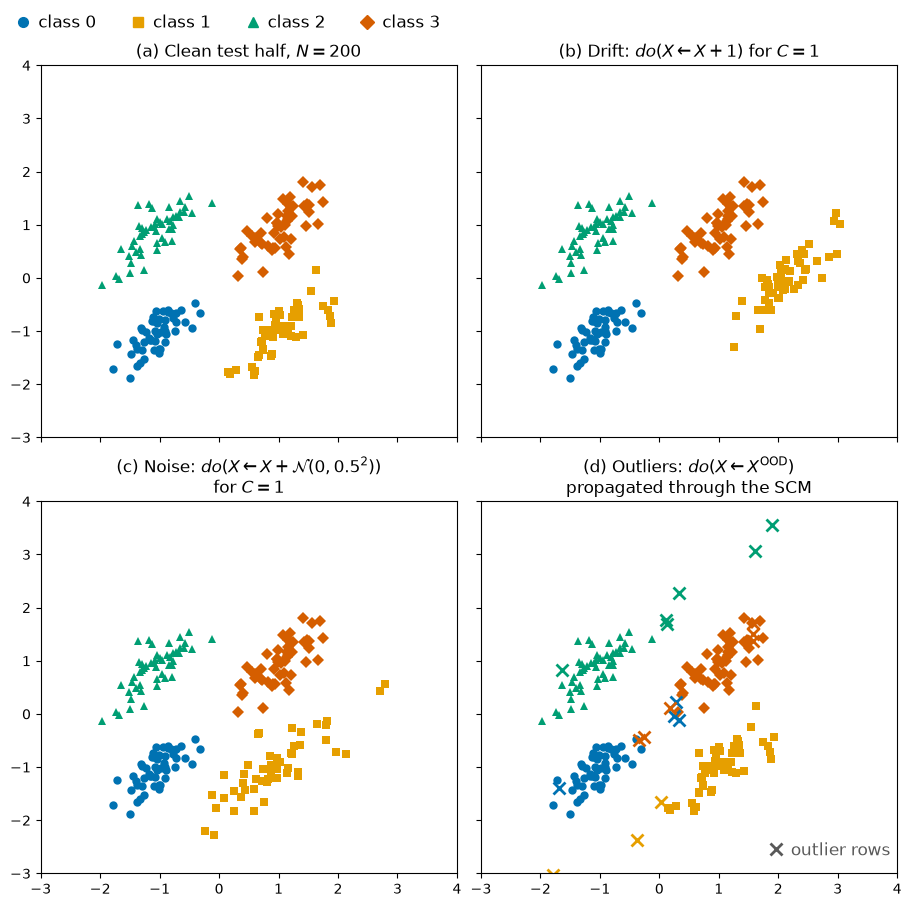

In [13]:
TITLES = {
    "drift": r"(b) Drift: $do(X \leftarrow X + 1)$ for $C = 1$",
    "noise": (r"(c) Noise: $do(X \leftarrow X + \mathcal{N}(0, 0.5^2))$"
              "\n"
              r"for $C = 1$"),
    "outliers": (r"(d) Outliers: $do(X \leftarrow X^{\mathrm{OOD}})$"
                 "\n"
                 "propagated through the SCM"),
}
# same 2x2 layout as the direct figure: clean test half (a) + causal variants
fig, axes = plt.subplots(2, 2, figsize=(9.0, 9.0), sharex=True, sharey=True,
                         constrained_layout=True)
ax = axes[0, 0]
scatter_classes(ax, X_test, y_test)
ax.set_title(r"(a) Clean test half, $N=200$")
for ax, name in zip(axes.flat[1:], ("drift", "noise", "outliers")):
    Xt, sc = CAUSAL[name]
    y_al = align_y(Xt, y_test, sc)
    if sc.observed is None:
        scatter_classes(ax, Xt, y_al)
    else:
        scatter_classes(ax, Xt, y_al, observed=sc.observed)
        outlier_marks(ax, Xt, y_al, ~sc.observed)
    ax.set_title(TITLES[name])
for ax in axes.flat:
    ax.set_xlim(-3, 4)
    ax.set_ylim(-3, 4)
class_legend(fig)
for name, (Xt, sc) in CAUSAL.items():
    print(f"{name:9s} rows: {len(Xt)}")


## Training predictors

`train_predictors` fits the three downstream predictors once, on the clean
train half, and returns them (all with `random_state=SEED` so the whole
notebook is reproducible):

- **clf** — `RandomForestClassifier`, features $(x, y)$ → class index (the
  `cls` column cast back to int)
- **reg** — `RandomForestRegressor`, features $x,c$ → x
  (treating the class index as a continuous blob coordinate)
- **det** — `IsolationForest`, unsupervised on $(x, y)$ only, with
  `contamination=0.1` to match the expected outlier rate

In [14]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier, RandomForestRegressor

def train_predictors(X):
    clf = RandomForestClassifier(
        n_estimators=100, random_state=SEED).fit(X[:, [0,1]], X[:, 2].astype(int))
    reg = RandomForestRegressor(
        n_estimators=100, random_state=SEED).fit(X[:, [0,2]], X[:, 1])
    det = IsolationForest(
        n_estimators=100, contamination=0.1, random_state=SEED).fit(X[:, [0,1]])
    return {"clf": clf, "reg": reg, "det": det}

predictors = train_predictors(X_train)

## Measuring how predictors react to the deficits

All three predictors are fitted once on the clean train half and then
frozen. Each table row evaluates them on one deficit variant of the test
half (`evaluate`, labels aligned via `align_y`: appended outlier rows keep
their seed row's class, read from the untouched `cls` cell). Columns:
classifier accuracy and macro $F_1$; regressor MSE and $R^2$ for the continuous $y$ target; detector mean anomaly score (higher = more normal), share flagged by
IsolationForest (contamination $= 0.1$), and share scoring above the clean
test half's 90th-percentile anomaly score $p_{90}$.

### Evaluation helpers

Two helpers make the generated outputs comparable to the clean test half:

- `align_y` rebuilds the ground-truth labels for the generated set. The
  in-place generators return the same 200 rows with the original labels; the
  outlier generators append 20 rows that are *copies of seed rows*, so their
  class is read from the untouched `cls` cell of the generated matrix
  (`Xt[len(y):, 2]`).
- `evaluate` scores the three frozen predictors on the generated set
  `Xt = (x, y, cls)`: classifier accuracy and macro $F_1$; regressor MSE and
  $R^2$ for continuous $y$; detector mean anomaly score (higher = more
  normal), share flagged by `IsolationForest.predict() == -1`, and share
  scoring above the clean test half's 90th-percentile anomaly score
  `p90_clean`. It returns a flat metric dict for the impact table plus an
  `extra` dict covering the appended rows only (share flagged / above
  $p_{90}$ among the outliers themselves).

In [15]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score

def evaluate(sc, predictors, Xt, y_full):
    '''Metrics on the full generated test set (labels aligned via align_y).'''

    y_true = Xt[:, 1]

    yp = predictors["clf"].predict(Xt[:, [0,1]])
    yrp = predictors["reg"].predict(Xt[:, [0,2]])
    scores = predictors["det"].score_samples(Xt[:, [0,1]])
    flagged = predictors["det"].predict(Xt[:, [0,1]]) == -1

    obs = np.ones(len(Xt), dtype=bool) if sc.observed is None else sc.observed
    app = ~obs

    m = {
        "scenario": sc.name,
        "family": sc.family,
        "rows": int(len(Xt)),
        "clf_acc": accuracy_score(y_full, yp),
        "clf_f1m": f1_score(y_full, yp, average="macro"),
        "reg_mse": mean_squared_error(y_true, yrp),
        "reg_r2": r2_score(y_true, yrp),
        "det_score": scores.mean(),
        "det_flag%": 100.0 * flagged.mean()
    }
    extra = {"scenario": f"{sc.name} [{sc.family}]", "family": sc.family,
             "rows": len(Xt)}
    if app.any():
        extra["appended"] = int(app.sum())
        extra["app_flag%"] = 100.0 * flagged[app].mean()
    return m, extra

In [16]:

rows = []
for name, family, fn in SCENARIOS:
    sc = Scenario(name, family)
    Xt = fn(X_test, y_test, sc, dgp)
    y_full = align_y(Xt, y_test, sc)
    m, _ = evaluate(sc, predictors, Xt, y_full)
    rows.append(m)

metrics = pd.DataFrame(rows)[
    ["scenario", "family", "rows", "clf_acc", "clf_f1m",
     "reg_mse", "reg_r2", "det_score", "det_flag%"]]
metrics.round(3).set_index(["scenario", "family"]).sort_index().T

scenario   baseline    drift             noise          outliers         
family    reference   causal   direct   causal   direct   causal   direct
rows        200.000  200.000  200.000  200.000  200.000  220.000  220.000
clf_acc       0.990    0.850    0.990    0.965    0.980    0.927    0.927
clf_f1m       0.990    0.837    0.990    0.965    0.980    0.928    0.927
reg_mse       0.111    0.158    0.228    0.148    0.147    0.211    0.126
reg_r2        0.898    0.807    0.790    0.869    0.865    0.839    0.884
det_score    -0.497   -0.532   -0.527   -0.502   -0.504   -0.505   -0.502
det_flag%    16.000   33.500   35.000   18.500   21.000   20.909   18.182

### Applying the predictors to the transformed data

**Idea.** The three frozen predictors are applied **once** to every
transformed test set — the clean test half and the six deficit variants of
the two preceding sections (the same rows that were saved under
`generated-data/`) — and the predictions are kept in one inspectable data
structure: `PREDICTIONS` maps a case name to a DataFrame with one row per
generated row:

- `x`, `y` — observed feature `x` and continuous regression target `y`,
- `cls` — the true class (aligned via `align_y`) and the regressor's second input,
- `prediction_clf` — the classifier's predicted class index,
- `prediction_reg` — the regressor's predicted continuous `y` value,
- `prediction_det` — the detector's prediction (`-1` means flagged),
- `outlier` — `True` for the appended outlier rows (outlier cases only).

Everything below only *reads* `PREDICTIONS` — no predictor is called while
drawing.

In [17]:
def apply_predictors(Xt, y_al, observed, predictors):
    """Apply the three frozen predictors to one generated test set.

    Returns an inspectable DataFrame with the observed (x, y, cls) values
    and all three frozen predictors' outputs.
    """
    df = pd.DataFrame(Xt[:, :2], columns=["x", "y"])
    df["cls"] = np.asarray(y_al).astype(int)
    df["prediction_clf"] = predictors["clf"].predict(Xt[:, [0, 1]])
    df["prediction_reg"] = predictors["reg"].predict(Xt[:, [0, 2]])
    df["prediction_det"] = predictors["det"].predict(Xt[:, [0, 1]])
    if observed is not None:
        df["outlier"] = ~np.asarray(observed, dtype=bool)
    return df


# one entry per transformed test set: the clean test half plus the six
# deficit variants of the two preceding sections
PREDICTIONS = {"test": apply_predictors(X_test, y_test, None, predictors)}
for family, scen in (("direct", DIRECT), ("causal", CAUSAL)):
    for name, (Xt, sc) in scen.items():
        observed = None if sc.observed is None else sc.observed
        PREDICTIONS[f"{family}-{name}"] = apply_predictors(
            Xt, align_y(Xt, y_test, sc), observed, predictors)

PREDICTIONS

{'test':             x         y  cls  prediction_clf  prediction_reg  prediction_det
 0    0.350248  0.544207    3               3        0.800141               1
 1   -1.476227 -1.427412    0               0       -1.529213              -1
 2   -1.136071 -0.817239    0               0       -1.222025               1
 3   -0.504159  1.533031    2               2        1.389069               1
 4   -0.645329 -0.600909    0               0       -0.656402               1
 ..        ...       ...  ...             ...             ...             ...
 195  0.952112 -0.809060    1               1       -0.939141               1
 196 -1.314292  0.434318    2               2        0.595576               1
 197 -1.509834  0.406070    2               2        0.395045              -1
 198  0.669585 -0.738377    1               1       -1.060369               1
 199  0.729360  0.632531    3               3        0.602403               1
 
 [200 rows x 6 columns],
 'direct-drift':             

### The frozen boundary grids

**Idea.** The decision functions are frozen — fitted once on the clean train
half — so their boundary images are computed **once** on dense $400 \times 400$ grids and
reused in the classifier and detector maps below. The classifier colors
each grid cell with the winning class, faded toward white by the vote
margin ($\sqrt{\max p}$). Regression is shown separately as
class-conditioned step curves: the model input is $(x, cls)$ and its
continuous output is $y$.

In [18]:
# the boundaries are frozen: evaluate the three grids once, reuse them in
# every panel below -- only the overlaid points differ
grid_clf = DecisionBoundaryDisplay.from_estimator(
    predictors["clf"], X_train[:, [0,1]], grid_resolution=400, eps=1.5,
    response_method="predict_proba")
best = np.argmax(grid_clf.response, axis=-1)
w = np.clip(np.max(grid_clf.response, axis=-1), 0.0, 1.0) ** 0.5
rgba = np.ones((*best.shape, 4))
for k, color in enumerate(CLASS_COLORS):
    r, g, b = to_rgb(color)
    ix = best == k
    for ch, v in ((0, r), (1, g), (2, b)):
        rgba[ix, ch] = w[ix] * v + (1.0 - w[ix])
rgba[..., 3] = 0.55

grid_det = DecisionBoundaryDisplay.from_estimator(
    predictors["det"], X_train[:, [0,1]], grid_resolution=400, eps=1.5,
    response_method="decision_function")
# from_estimator leaves its scratch figures open; the grids are only
# consumed as data below, so close them to keep the notebook clean
plt.close("all")


### Drawing helpers

**Idea.** All per-point drawing reads the stored predictions, never the
predictors. A row is drawn in a **darker shade** of its class color when the
panel's predictor handles it wrong — `wrong_clf` flags rows whose predicted
class differs from the true one. `wrong_reg` marks rows whose continuous
prediction differs from the observed $y$ by more than $0.5$ target units.
`overlay` draws rows class by class with white rims and stamps appended
outliers with class-colored $\times$ marks.

In [19]:
def darken(color, f=0.45):
    """Blend a class color toward black (f = fraction of brightness kept)."""
    color = color.lstrip("#")
    r, g, b = (int(color[i:i + 2], 16) for i in (0, 2, 4))
    return "#{:02x}{:02x}{:02x}".format(round(r * f), round(g * f), round(b * f))


def wrong_clf(df):
    """Rows the frozen classifier assigns to another class than the true one."""
    return df["prediction_clf"].to_numpy() != df["cls"].to_numpy()


def wrong_reg(df):
    """Rows whose continuous y prediction misses the observed y by > 0.5."""
    return np.abs(df["prediction_reg"].to_numpy() - df["y"].to_numpy()) > 0.5


def overlay(ax, X2, y_true, observed=None, wrong=None, ms=6.0):
    """Rows in their true class color (white rims); rows in `wrong` darker."""
    if wrong is None:
        scatter_classes(ax, X2, y_true, observed=observed, ms=ms,
                        edgecolor="white", mew=0.5)
    else:
        obs = np.ones(len(X2), dtype=bool) if observed is None else observed
        scatter_classes(ax, X2, y_true, observed=obs & ~wrong, ms=ms,
                        edgecolor="white", mew=0.5)
        scatter_classes(ax, X2, y_true, observed=obs & wrong, ms=ms,
                        edgecolor="white", mew=0.5, color_fn=darken)
    if observed is not None:
        outlier_marks(ax, X2, y_true, ~observed, wrong=wrong,
                      show_caption=False)


WRONG_HANDLE = Line2D([], [], marker="o", markersize=8, color="0.15",
                      linestyle="none", label="wrong prediction (darker)")


def boundary_legend(fig):
    outlier_handle = Line2D([], [], marker="x", markersize=8, color="0.35",
                            linestyle="none", label="outlier rows")
    fig.legend(handles=[*CLASS_HANDLES, WRONG_HANDLE, outlier_handle],
               loc="outside upper left", ncols=6, fontsize=12, frameon=False,
               handlelength=1.4, handletextpad=0.4, columnspacing=1.2)





def plot_classifier(ax, predictions, grid, rgba):
    """Draw the classifier map and its case observations on an Axes."""
    extent = (grid.xx0.min(), grid.xx0.max(),
              grid.xx1.min(), grid.xx1.max())
    ax.imshow(rgba, origin="lower", extent=extent, aspect="auto",
              interpolation="nearest")
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    X2 = predictions[["x", "y"]].to_numpy()
    y_true = predictions["cls"].to_numpy()
    observed = (None if "outlier" not in predictions
                else ~predictions["outlier"].to_numpy())
    overlay(ax, X2, y_true, observed, wrong=wrong_clf(predictions))
    return ax


def plot_detector(ax, predictions, grid):
    """Draw the detector score map and its case observations on an Axes."""
    ax.contourf(grid.xx0, grid.xx1, -grid.response, cmap="RdYlGn_r",
                levels=21, vmin=-0.35, vmax=0.35, extend="both", alpha=0.8)
    ax.contour(grid.xx0, grid.xx1, -grid.response, levels=[0.0],
               colors="0.15", linewidths=1.8)
    ax.set_xlim(grid.xx0.min(), grid.xx0.max())
    ax.set_ylim(grid.xx1.min(), grid.xx1.max())
    X2 = predictions[["x", "y"]].to_numpy()
    y_true = predictions["cls"].to_numpy()
    observed = (None if "outlier" not in predictions
                else ~predictions["outlier"].to_numpy())
    overlay(ax, X2, y_true, observed)
    return ax


def plot_regression(ax, predictions, regressor, x_grid):
    """Draw class-conditioned regression curves and observations on an Axes."""
    wrong = wrong_reg(predictions)
    appended = (predictions["outlier"].to_numpy() if "outlier" in predictions
                else np.zeros(len(predictions), dtype=bool))
    y_classes = predictions["cls"].to_numpy()
    for cls, color in enumerate(CLASS_COLORS):
        model_input = np.column_stack([x_grid, np.full(len(x_grid), cls)])
        y_grid = regressor.predict(model_input)
        ax.step(x_grid, y_grid, where="post", color=color,
                linewidth=0.9, zorder=2)
        selected = y_classes == cls
        for is_wrong in (False, True):
            point_color = darken(color) if is_wrong else color
            points = selected & (wrong == is_wrong)
            ordinary = points & ~appended
            outliers = points & appended
            ax.scatter(predictions.loc[ordinary, "x"],
                       predictions.loc[ordinary, "y"], color=point_color,
                       marker=CLASS_MARKERS[cls], edgecolor="white",
                       linewidth=0.5, s=34, zorder=3)
            ax.scatter(predictions.loc[outliers, "x"],
                       predictions.loc[outliers, "y"], color=point_color,
                       marker="x", linewidth=1.8, s=55, zorder=4)
    return ax


### Assembling the figures

**Idea.** Each display cell owns the layout: one figure row per
`(label, case)` pair, calling one renderer per Axes — `plot_classifier`
draws the frozen classifier decision-boundary map, `plot_detector` the
detector score map — each in its own figure with the stored points from
`PREDICTIONS`. The class/error/outlier legend is added at figure level in
the classifier cells, the detector colorbar in the detector cells. Both
maps use the same $(x, y)$ feature plane. Regression uses a different
input plane and is shown in the following class-conditioned plots.


### Class-conditioned regression curves

**Idea.** The regressor predicts continuous $y$ from $(x, cls)$. Each
scenario has one plot containing all four classes: the class-colored
step curves show the forest prediction against $x$, and matching markers
show the observed $(x, y)$ values. Darker points have absolute prediction
error above $0.5$ $y$ units; appended outlier rows use $\times$ markers.


### (i) Classifier and detector maps over the clean test data

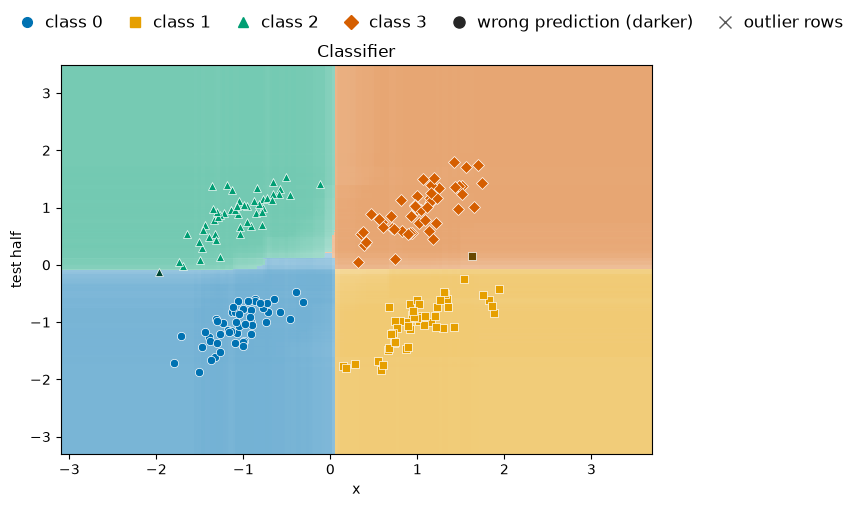

In [20]:
rows = [("test half", "test")]
fig, ax = plt.subplots(1, 1, figsize=(6.5, 5), constrained_layout=True)
for label, case in rows:
    plot_classifier(ax, PREDICTIONS[case], grid_clf, rgba)
    ax.set_ylabel(label)
    ax.set_title("Classifier")
ax.set_xlabel("x")
boundary_legend(fig)


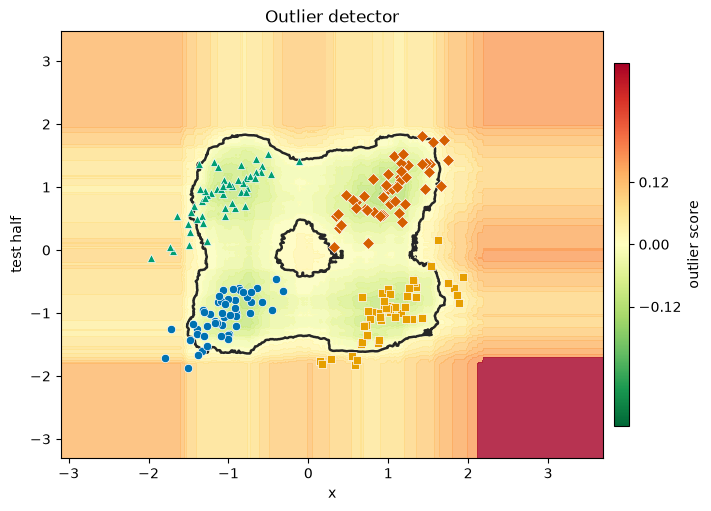

In [21]:
rows = [("test half", "test")]
fig, ax = plt.subplots(1, 1, figsize=(7.0, 5), constrained_layout=True)
for label, case in rows:
    plot_detector(ax, PREDICTIONS[case], grid_det)
    ax.set_ylabel(label)
    ax.set_title("Outlier detector")
ax.set_xlabel("x")
fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-0.35, vmax=0.35), cmap="RdYlGn_r"),
    ax=ax, shrink=0.85, aspect=25, pad=0.02, ticks=[-0.12, 0, 0.12],
).set_label("outlier score")


### Regression over the clean test data

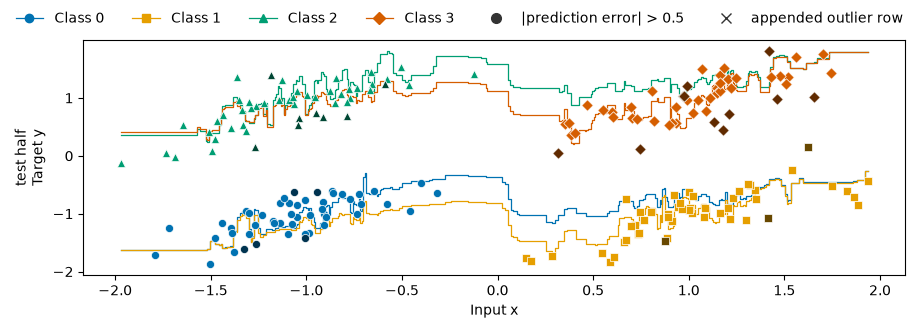

In [22]:
x_values = PREDICTIONS["test"]["x"].to_numpy()
x_grid = np.linspace(x_values.min(), x_values.max(), 500)
fig_reg, axes_reg = plt.subplots(
    1, 1, figsize=(9.0, 3.2), sharex=True, sharey=True,
    squeeze=False, constrained_layout=True,
)
class_handles = [
    Line2D([], [], color=color, marker=CLASS_MARKERS[cls], linewidth=0.9,
           label=f"Class {cls}")
    for cls, color in enumerate(CLASS_COLORS)
]
wrong_handle = Line2D([], [], marker="o", markersize=7, color="0.2",
                      linestyle="none", label="|prediction error| > 0.5")
outlier_handle = Line2D([], [], marker="x", markersize=7, color="0.2",
                        linestyle="none", label="appended outlier row")
ax = axes_reg[0, 0]
plot_regression(ax, PREDICTIONS["test"], predictors["reg"], x_grid)
ax.set_ylabel("test half\nTarget y")
ax.set_xlabel("Input x")
_ = fig_reg.legend(
    handles=[*class_handles, wrong_handle, outlier_handle],
    loc="outside upper center", ncols=6, frameon=False,
)


### (ii) Boundaries over the direct (non-causal) deficits

Rows: drift, noise, outliers (direct). The classifier and detector maps
remain frozen; only the points change.

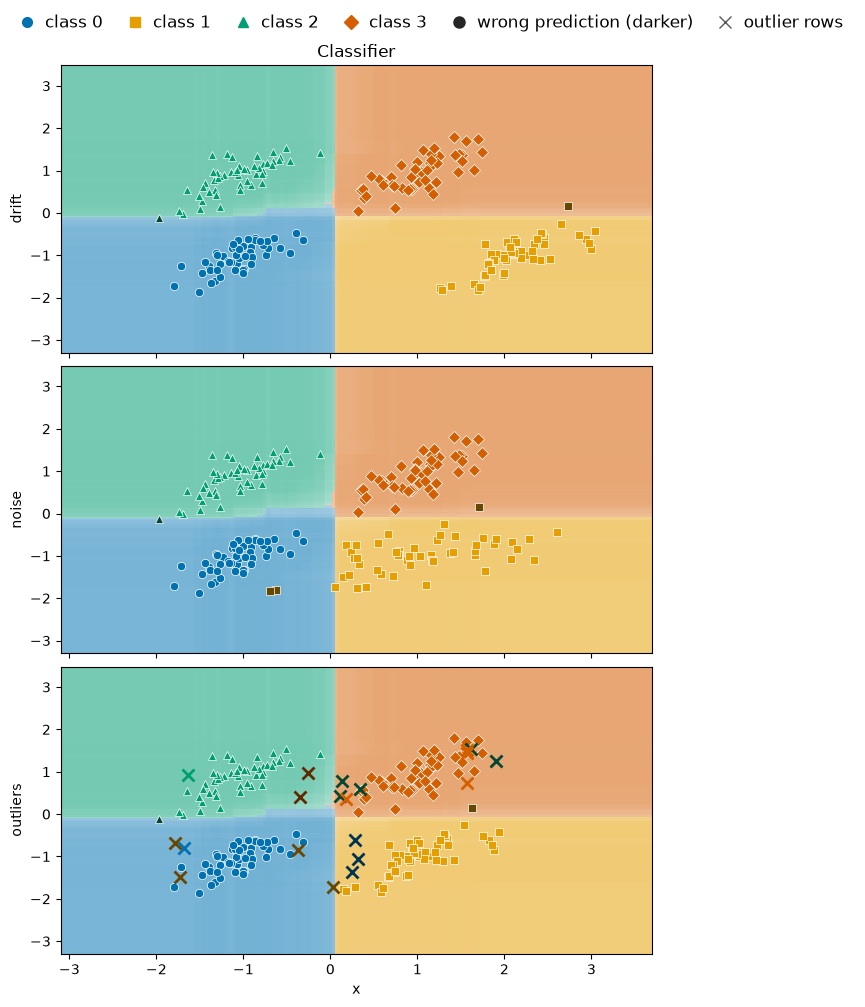

In [23]:
rows = [('drift', 'direct-drift'), ('noise', 'direct-noise'), ('outliers', 'direct-outliers')]
fig, axes = plt.subplots(len(rows), 1, figsize=(6.5, 10), sharex=True,
                         sharey=True, constrained_layout=True)
for row, (label, case) in enumerate(rows):
    plot_classifier(axes[row], PREDICTIONS[case], grid_clf, rgba)
    axes[row].set_ylabel(label)
axes[0].set_title("Classifier")
axes[-1].set_xlabel("x")
boundary_legend(fig)


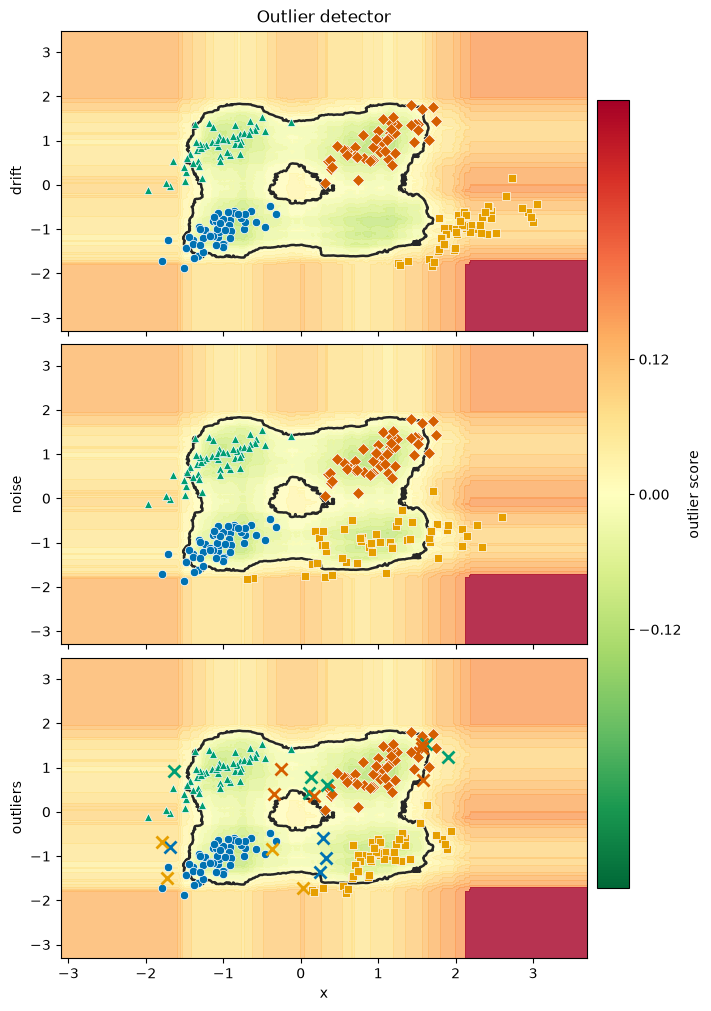

In [24]:
rows = [('drift', 'direct-drift'), ('noise', 'direct-noise'), ('outliers', 'direct-outliers')]
fig, axes = plt.subplots(len(rows), 1, figsize=(7.0, 10), sharex=True,
                         sharey=True, constrained_layout=True)
for row, (label, case) in enumerate(rows):
    plot_detector(axes[row], PREDICTIONS[case], grid_det)
    axes[row].set_ylabel(label)
axes[0].set_title("Outlier detector")
axes[-1].set_xlabel("x")
fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-0.35, vmax=0.35), cmap="RdYlGn_r"),
    ax=axes, shrink=0.85, aspect=25, pad=0.02, ticks=[-0.12, 0, 0.12],
).set_label("outlier score")


### Regression over direct deficits

The clean test row is included as a baseline for the three
transformed sets.


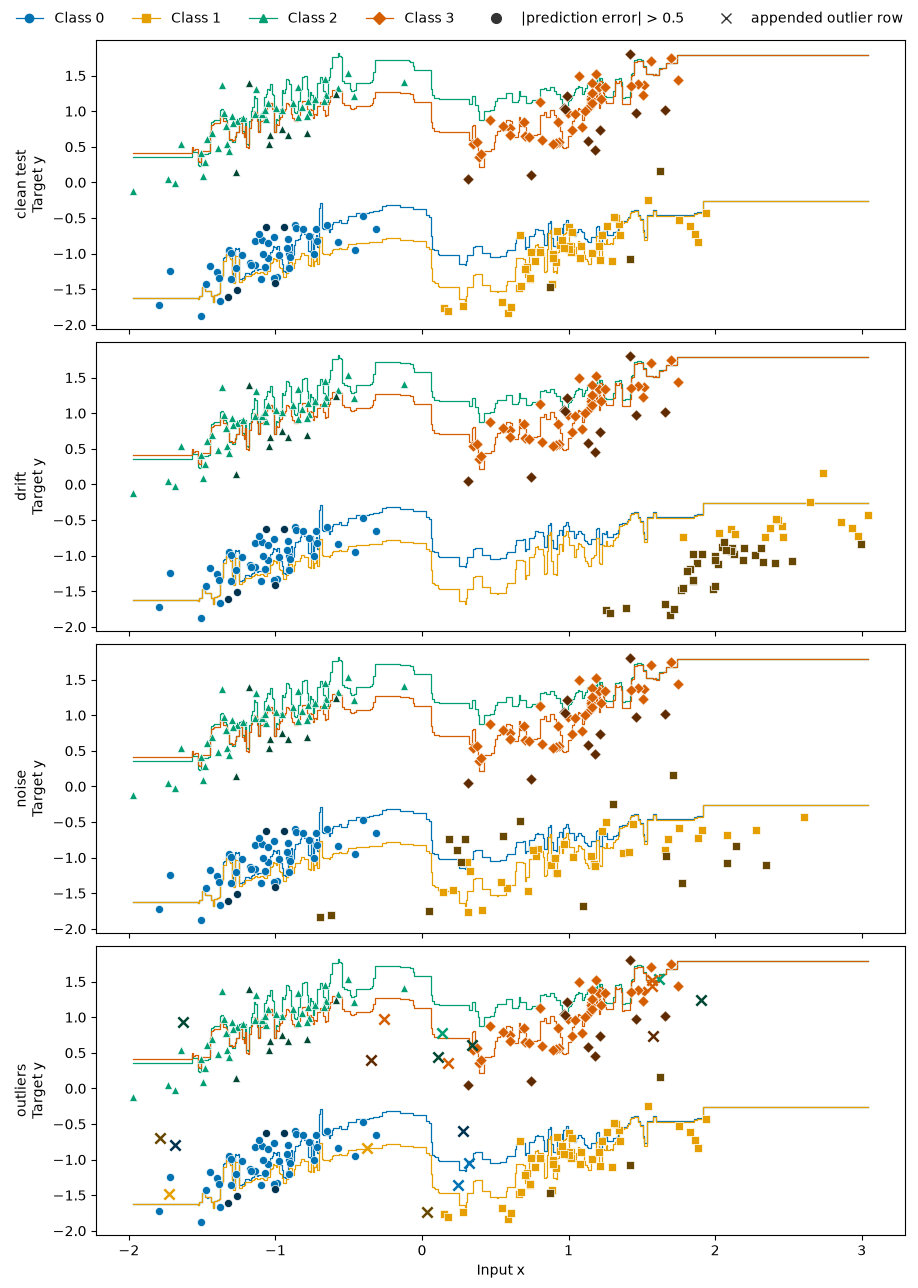

In [25]:
rows = [('clean test', 'test'), ('drift', 'direct-drift'), ('noise', 'direct-noise'), ('outliers', 'direct-outliers')]
x_values = np.concatenate([
    PREDICTIONS[case]["x"].to_numpy() for _, case in rows
])
x_grid = np.linspace(x_values.min(), x_values.max(), 500)
fig_reg, axes_reg = plt.subplots(
    len(rows), 1, figsize=(9.0, 3.2 * len(rows)), sharex=True, sharey=True,
    squeeze=False, constrained_layout=True,
)
class_handles = [
    Line2D([], [], color=color, marker=CLASS_MARKERS[cls], linewidth=0.9,
           label=f"Class {cls}")
    for cls, color in enumerate(CLASS_COLORS)
]
wrong_handle = Line2D([], [], marker="o", markersize=7, color="0.2",
                      linestyle="none", label="|prediction error| > 0.5")
outlier_handle = Line2D([], [], marker="x", markersize=7, color="0.2",
                        linestyle="none", label="appended outlier row")
for row, (label, case) in enumerate(rows):
    ax = axes_reg[row, 0]
    plot_regression(ax, PREDICTIONS[case], predictors["reg"], x_grid)
    ax.set_ylabel(f"{label}\nTarget y")
    if row == len(rows) - 1:
        ax.set_xlabel("Input x")
_ = fig_reg.legend(
    handles=[*class_handles, wrong_handle, outlier_handle],
    loc="outside upper center", ncols=6, frameon=False,
)


### (iii) Boundaries over the causal deficits

Same frozen classifier and detector maps, with the causal injection layer.

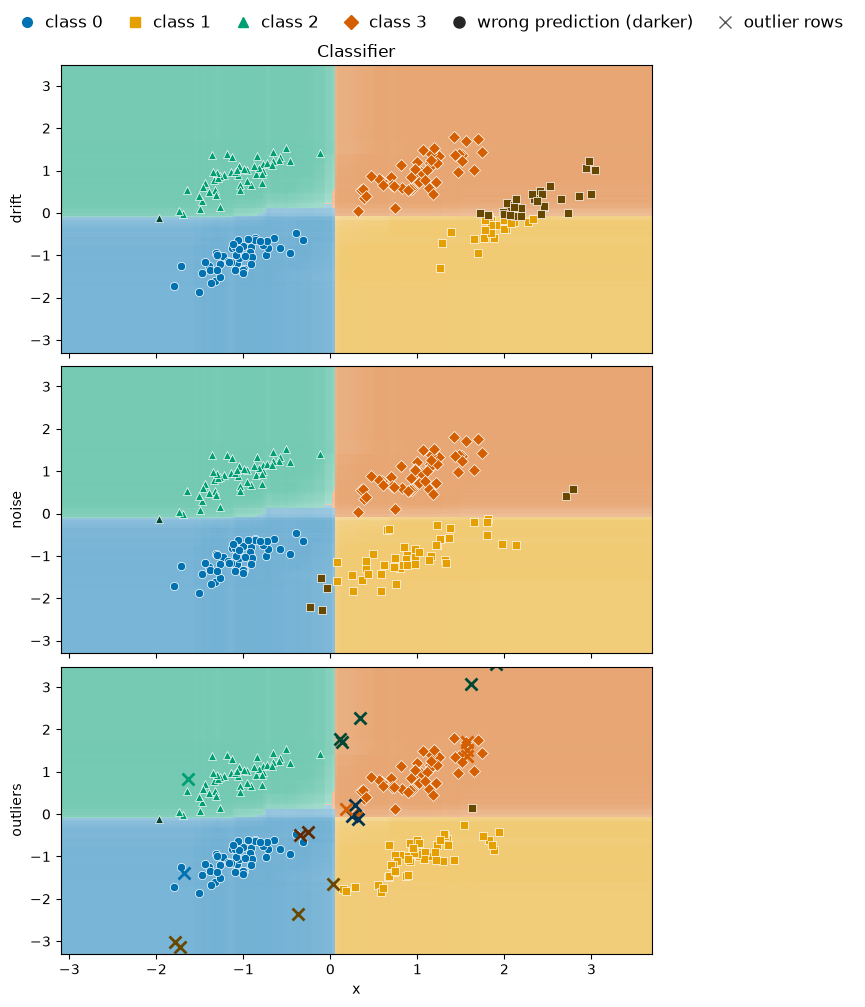

In [26]:
rows = [('drift', 'causal-drift'), ('noise', 'causal-noise'), ('outliers', 'causal-outliers')]
fig, axes = plt.subplots(len(rows), 1, figsize=(6.5, 10), sharex=True,
                         sharey=True, constrained_layout=True)
for row, (label, case) in enumerate(rows):
    plot_classifier(axes[row], PREDICTIONS[case], grid_clf, rgba)
    axes[row].set_ylabel(label)
axes[0].set_title("Classifier")
axes[-1].set_xlabel("x")
boundary_legend(fig)


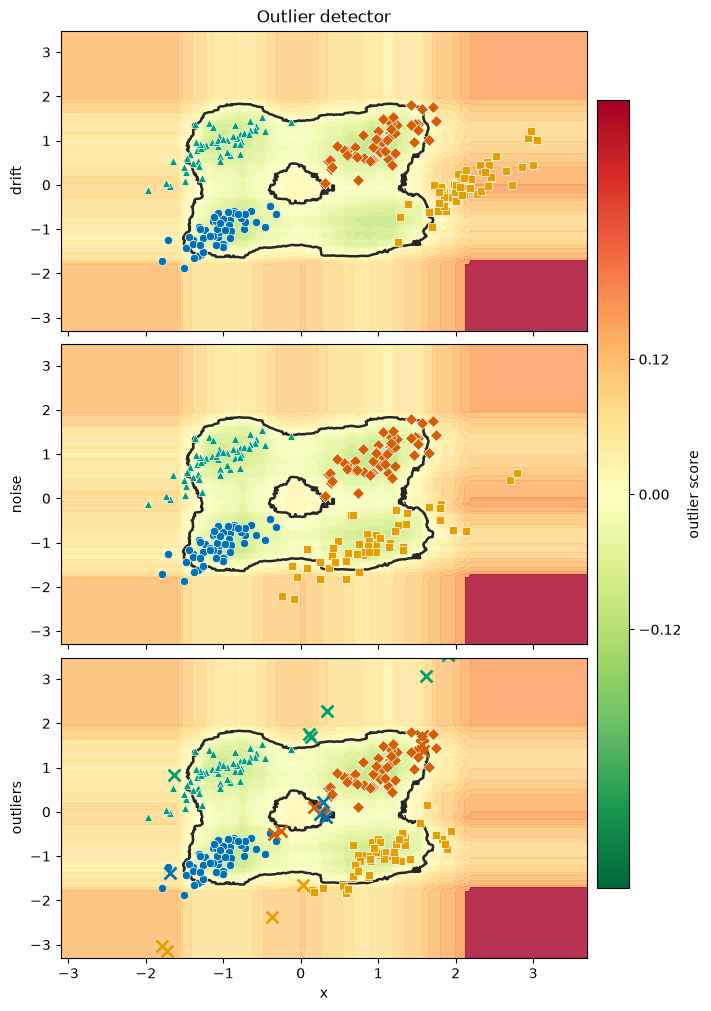

In [27]:
rows = [('drift', 'causal-drift'), ('noise', 'causal-noise'), ('outliers', 'causal-outliers')]
fig, axes = plt.subplots(len(rows), 1, figsize=(7.0, 10), sharex=True,
                         sharey=True, constrained_layout=True)
for row, (label, case) in enumerate(rows):
    plot_detector(axes[row], PREDICTIONS[case], grid_det)
    axes[row].set_ylabel(label)
axes[0].set_title("Outlier detector")
axes[-1].set_xlabel("x")
fig.colorbar(
    ScalarMappable(norm=Normalize(vmin=-0.35, vmax=0.35), cmap="RdYlGn_r"),
    ax=axes, shrink=0.85, aspect=25, pad=0.02, ticks=[-0.12, 0, 0.12],
).set_label("outlier score")


### Regression over causal deficits

The clean test row is included as a baseline for the three
causal transformations.


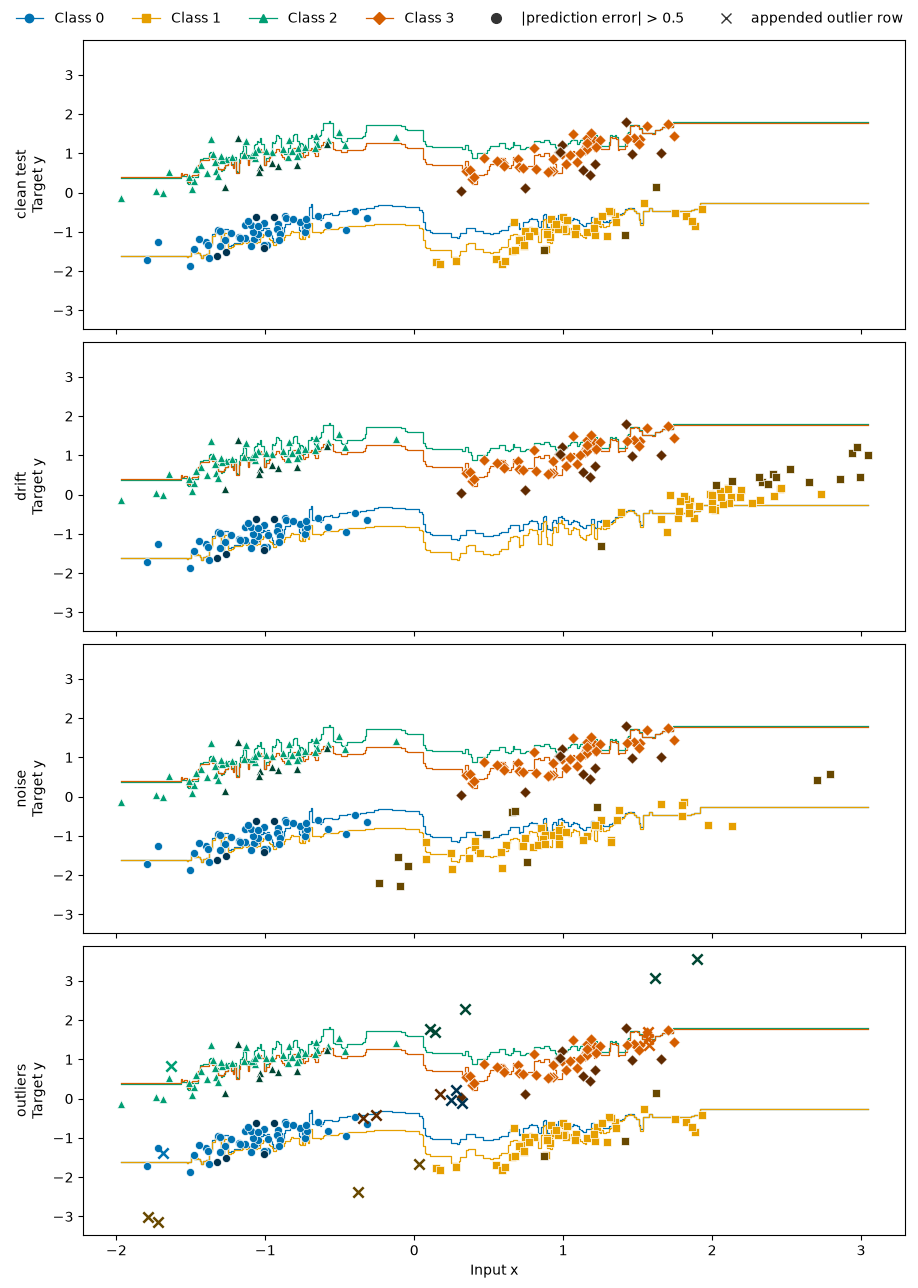

In [28]:
rows = [('clean test', 'test'), ('drift', 'causal-drift'), ('noise', 'causal-noise'), ('outliers', 'causal-outliers')]
x_values = np.concatenate([
    PREDICTIONS[case]["x"].to_numpy() for _, case in rows
])
x_grid = np.linspace(x_values.min(), x_values.max(), 500)
fig_reg, axes_reg = plt.subplots(
    len(rows), 1, figsize=(9.0, 3.2 * len(rows)), sharex=True, sharey=True,
    squeeze=False, constrained_layout=True,
)
class_handles = [
    Line2D([], [], color=color, marker=CLASS_MARKERS[cls], linewidth=0.9,
           label=f"Class {cls}")
    for cls, color in enumerate(CLASS_COLORS)
]
wrong_handle = Line2D([], [], marker="o", markersize=7, color="0.2",
                      linestyle="none", label="|prediction error| > 0.5")
outlier_handle = Line2D([], [], marker="x", markersize=7, color="0.2",
                        linestyle="none", label="appended outlier row")
for row, (label, case) in enumerate(rows):
    ax = axes_reg[row, 0]
    plot_regression(ax, PREDICTIONS[case], predictors["reg"], x_grid)
    ax.set_ylabel(f"{label}\nTarget y")
    if row == len(rows) - 1:
        ax.set_xlabel("Input x")
_ = fig_reg.legend(
    handles=[*class_handles, wrong_handle, outlier_handle],
    loc="outside upper center", ncols=6, frameon=False,
)


### What to observe

- **Direct drift** moves points, but the frozen decision functions still
  assign almost every row correctly — the metrics barely move.
- **Causal drift** shifts the whole $y \mid x$ mechanism: rows cross the
  frozen plates and seams, and every predictor metric drops.
- The **darker rows** in the classifier map are misclassified. In the
regression curves, darker points have absolute $y$ prediction error above
$0.5$; compare each transformed row with the clean test baseline.
- The detector reacts only to *where* rows sit, so it flags whatever leaves
  the training density — direct and causal variants look similar to it
  (see the `det_flag%` column).
